In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("stock_prices.csv")

df["date"] = pd.to_datetime(df["date"])

print(f"Dataset shape: {df.shape}")
print(f"Number of stocks: {df['symbol'].nunique()}")
print(f"Period: {df['date'].min().date()} to {df['date'].max().date()}")

display(df.head())
display(df.describe())

print("Missing values:")
print(df.isna().sum())

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate stock-date pairs:", df.duplicated(subset=["symbol", "date"]).sum())

observations_per_stock = df.groupby("symbol").size()
print("Observations per stock:")
display(observations_per_stock.describe())

print("Stocks with fewer than 1007 observations:")
display(observations_per_stock[observations_per_stock < 1007])

invalid_high_low = df["high"] < df["low"]
invalid_close = ((df["close"] < df["low"])| (df["close"] > df["high"]))
print("Rows where high < low:", invalid_high_low.sum())
print("Closing prices outside the daily range:", invalid_close.sum())

Dataset shape: (497472, 7)
Number of stocks: 505
Period: 2014-01-02 to 2017-12-29


,symbol,date,open,high,low,close,volume
0,AAL,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,2014-01-02,70.1100,70.2300,69.4800,69.8900,1148391


,date,open,high,low,close,volume
count,497472,497461.000000,497464.000000,497464.000000,497472.000000,4.974720e+05
mean,2016-01-06 17:16:00.439984,86.352275,87.132562,85.552467,86.369082,4.253611e+06
min,2014-01-02 00:00:00,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,2015-01-08 00:00:00,41.690000,42.090000,41.280000,41.703750,1.080166e+06
50%,2016-01-11 00:00:00,64.970000,65.560000,64.353700,64.980000,2.084896e+06
75%,2017-01-06 00:00:00,98.410000,99.230000,97.580000,98.420000,4.271928e+06
max,2017-12-29 00:00:00,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08
std,NaN,101.471228,102.312062,100.570957,101.472407,8.232139e+06


Missing values:
symbol     0
date       0
open      11
high       8
low        8
close      0
volume     0
dtype: int64
Exact duplicate rows: 0
Duplicate stock-date pairs: 0
Observations per stock:


count     505.000000
mean      985.093069
std       118.785643
min        18.000000
25%      1007.000000
50%      1007.000000
75%      1007.000000
max      1007.000000
dtype: float64

Stocks with fewer than 1007 observations:


symbol
APTV      18
BHF      117
BHGE     126
CFG      824
CSRA     535
DHR      995
DWDP      83
DXC      189
ES       997
EVHC     271
FTV      378
GOOG     949
HLT      250
HPE      555
HPQ      555
ICE     1006
INFO     891
KHC      629
NAVI     934
O        995
PYPL     629
QRVO     755
SYF      862
UA       438
WLTW     502
WRK      636
dtype: int64

Rows where high < low: 1
Closing prices outside the daily range: 9


In [17]:
# Daily returns 
df = df.sort_values(["symbol", "date"]).copy()

df["daily_return"] = df.groupby("symbol")["close"].pct_change()

print("Missing returns:", df["daily_return"].isna().sum())
print("Positive returns:", (df["daily_return"] > 0).sum())
print("Negative returns:", (df["daily_return"] < 0).sum())

# Daily volatility by Symbol
daily_volatility = df.groupby("symbol")["daily_return"].std()

# Annual volatility
annual_volatility = daily_volatility * np.sqrt(252)

print(annual_volatility.describe())

print(annual_volatility.sort_values(ascending=False).head(10))

print("Exemple with the stock AAPL")
print(f"Daily volatility: {daily_volatility['AAPL']:.2%}")
print(f"Annualized volatility: {annual_volatility['AAPL']:.2%}")

Missing returns: 505
Positive returns: 258110
Negative returns: 234725
count    505.000000
mean       0.247473
std        0.079817
min        0.131510
25%        0.193777
50%        0.228453
75%        0.279346
max        0.722536
Name: daily_return, dtype: float64
symbol
CHK     0.722536
AMD     0.620720
LNT     0.587453
FCX     0.587182
BHGE    0.581240
WMB     0.513500
MRO     0.510581
EVHC    0.469141
RRC     0.461517
INCY    0.453382
Name: daily_return, dtype: float64
Exemple with the stock AAPL
Daily volatility: 1.43%
Annualized volatility: 22.71%


In [25]:
# Historical drawdown
df = df.sort_values(["symbol", "date"]).copy()

df["wealth_index"] = ((1 + df["daily_return"].fillna(0)).groupby(df["symbol"]).cumprod())

df["running_max"] = (df.groupby("symbol")["wealth_index"].cummax())

df["drawdown"] = (df["wealth_index"] / df["running_max"] - 1)

max_drawdown = df.groupby("symbol")["drawdown"].min()

print("10 largest maximum drawdowns:")
display(max_drawdown.sort_values().head(10))

10 largest maximum drawdowns:


symbol
CHK     -0.949201
FCX     -0.904201
MRO     -0.838570
RRC     -0.833191
DISCK   -0.818430
DISCA   -0.817284
WMB     -0.816628
WYNN    -0.792297
UAA     -0.776945
UA      -0.768423
Name: drawdown, dtype: float64

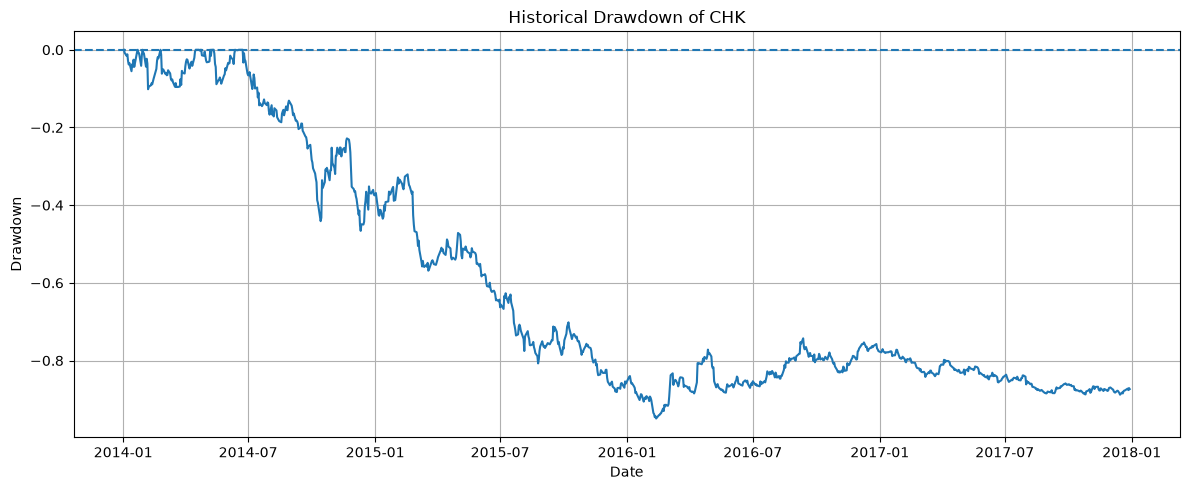

In [36]:
import matplotlib.pyplot as plt

# Choose an action
action = "CHK"
stock = df[df["symbol"] == action].copy()

plt.figure(figsize=(12, 5))
plt.plot(stock["date"], stock["drawdown"])

plt.title(f"Historical Drawdown of {action}")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.axhline(y=0, linestyle="--")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# VaR and CVaR

# Historical VaR and CVaR at 95% for AAPL
aapl_returns = df.loc[df["symbol"] == "AAPL", "daily_return"].dropna()

confidence_level = 0.95
alpha = 1 - confidence_level

return_th = aapl_returns.quantile(alpha)

var_95 = -return_th
cvar_95 = -aapl_returns[aapl_returns <= return_th].mean()

print(f"VaR (95%): {var_95:.2%}")
print(f"CVaR (95%): {cvar_95:.2%}")

VaR (95%): 2.25%
CVaR (95%): 3.23%


,symbol,VaR_95,CVaR_95
95,CHK,0.065491,0.097279
68,BHGE,0.030034,0.085982
182,FCX,0.054857,0.083157
32,AMD,0.051931,0.080531
486,WMB,0.037602,0.073938
320,MRO,0.046896,0.071731
453,UA,0.036557,0.069608
403,RRC,0.046225,0.065693
172,EVHC,0.032303,0.064918
341,NRG,0.037804,0.063884


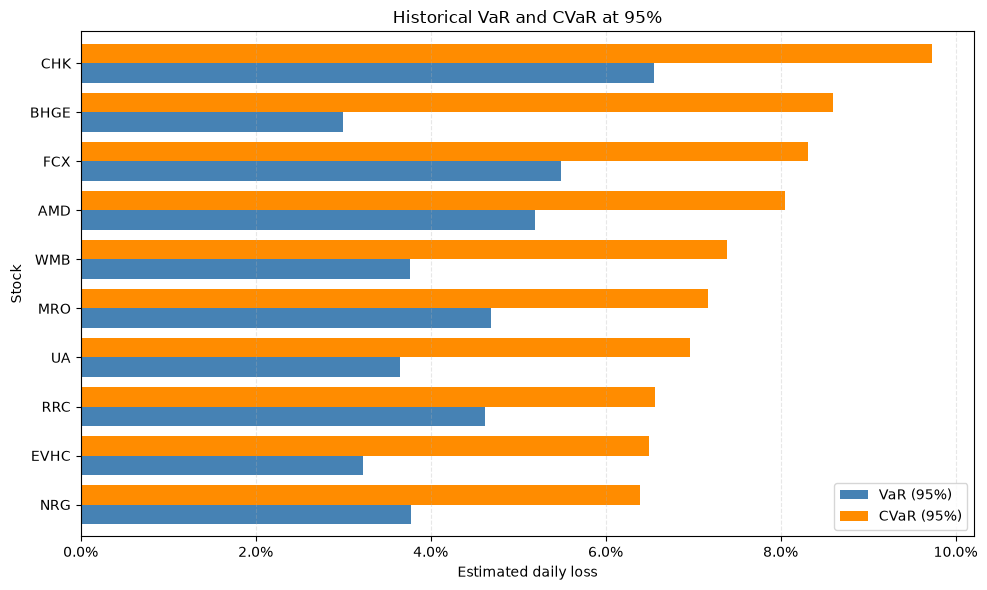

In [38]:
# Historical VaR and CVaR at 95% for all stocks

alpha = 0.05
results = []

for symbol, group in df.groupby("symbol"):

    returns = group["daily_return"].dropna()

    if returns.empty:
        continue

    threshold = returns.quantile(alpha)
    var_95 = -threshold
    cvar_95 = -returns[returns <= threshold].mean()

    results.append({
        "symbol": symbol,
        "VaR_95": var_95,
        "CVaR_95": cvar_95
    })

risques = pd.DataFrame(results)

risques = risques.sort_values("CVaR_95", ascending=False)

display(risques.head(10))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Select the 10 stocks with the highest CVaR
top10 = risques.head(10).sort_values("CVaR_95")

ax = top10.plot(
    kind="barh",
    x="symbol",
    y=["VaR_95", "CVaR_95"],
    figsize=(10, 6),
    color=["steelblue", "darkorange"],
    width=0.8
)

ax.set_xlabel("Estimated daily loss")
ax.set_ylabel("Stock")
ax.set_title("Historical VaR and CVaR at 95%")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(["VaR (95%)", "CVaR (95%)"])
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# Historical VaR backtesting
window = 250
alpha = 0.05

df_backtest = df.sort_values(["symbol", "date"]).copy()

df_backtest["var_threshold"] = (df_backtest.groupby("symbol")["daily_return"].transform(lambda r: r.shift(1).rolling(window=window, min_periods=window).quantile(alpha)))

df_backtest["var_95"] = -df_backtest["var_threshold"]

df_backtest["exception"] = (df_backtest["daily_return"] < df_backtest["var_threshold"])

tests = df_backtest.dropna(subset=["var_threshold", "daily_return"])

backtest = (tests.groupby("symbol").agg(number_of_tests=("exception", "size"),number_of_exceptions=("exception", "sum"),exception_rate=("exception", "mean"),).reset_index())

backtest["expected_exceptions"] = (backtest["number_of_tests"] * alpha)

backtest = backtest.sort_values("exception_rate", ascending=False)

display(backtest.head(10))

,symbol,number_of_tests,number_of_exceptions,exception_rate,expected_exceptions
355,PDCO,756,59,0.078042,37.8
262,KIM,756,58,0.076720,37.8
269,KR,756,57,0.075397,37.8
196,GGP,756,57,0.075397,37.8
120,CTL,756,55,0.072751,37.8
341,NWL,756,55,0.072751,37.8
420,STX,756,54,0.071429,37.8
392,RL,756,54,0.071429,37.8
474,WDC,756,54,0.071429,37.8
489,XL,756,54,0.071429,37.8


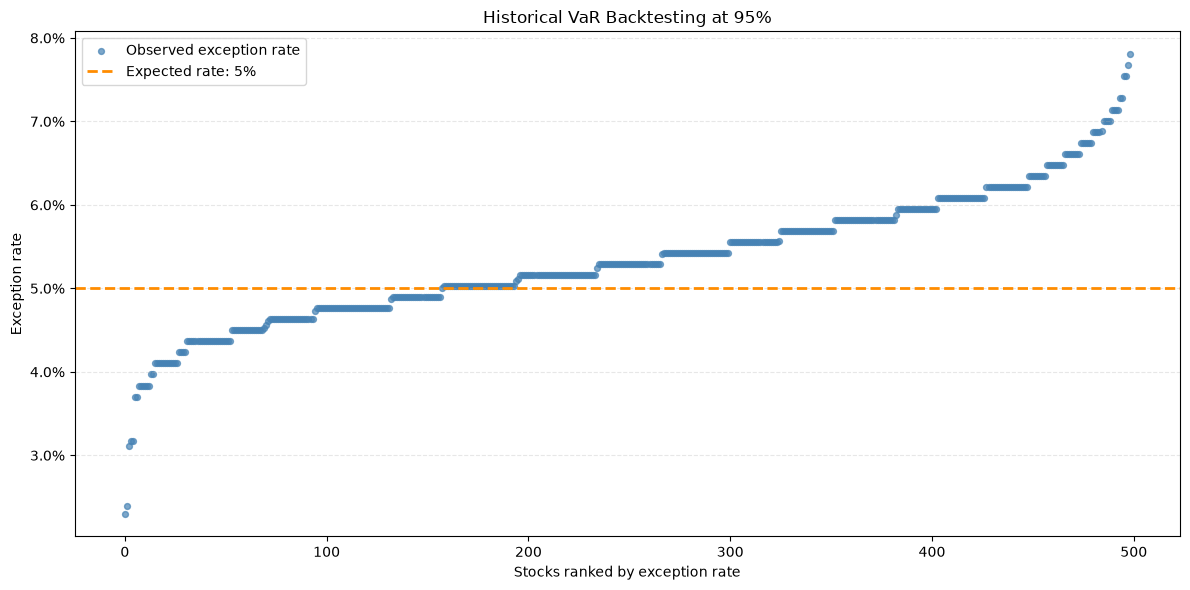

In [39]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

backtest_sorted = (
    backtest.sort_values("exception_rate")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(
    range(len(backtest_sorted)),
    backtest_sorted["exception_rate"],
    s=18,
    alpha=0.7,
    color="steelblue",
    label="Observed exception rate"
)

ax.axhline(
    y=0.05,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label="Expected rate: 5%"
)

# Format the y-axis as percentages
ax.yaxis.set_major_formatter(
    mtick.PercentFormatter(1.0)
)

ax.set_xlabel("Stocks ranked by exception rate")
ax.set_ylabel("Exception rate")
ax.set_title("Historical VaR Backtesting at 95%")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
### Interpretation of the VaR Backtesting
#The backtesting procedure uses a rolling window of 250 daily returns to estimate the historical VaR at the 95% confidence level. 
#The estimated threshold is then compared with the return observed on the following trading day.
#Under a correctly calibrated VaR model, approximately 5% of returns should fall below the estimated threshold over a sufficiently large number of observations.
#The results show how exception rates vary across the stocks in the dataset. Stocks with exception rates above 5% experienced more losses beyond the estimated VaR than expected.
#This may indicate that the model does not fully capture their downside risk.
#However, an exception rate above 5% does not necessarily imply that the model is statistically inadequate.
#The results should be interpreted in light of the number of observations, changes in market volatility and the possibility of clustered exceptions.
#Overall, this analysis provides a useful first assessment of the historical VaR model. 
#Further statistical tests would be needed to evaluate its calibration and the independence of exceptions. 
#The results also depend on the quality and adjustment of the historical price data.